# NLP Capstone Project
## From Reviews to Retail Actions: NLP-Based Analysis of Drivers of Product Recommendation in Women's E-Commerce

### Dataset
Women's E-Commerce Clothing Reviews

### Objective
To analyze customer reviews using Natural Language Processing and identify patterns associated with product recommendations, generating actionable business insights for fashion retailers.

# STEP 1: IMPORT LIBRARIES AND LOAD THE DATASET

In [ ]:
# ============================================================
# STEP 1: IMPORT LIBRARIES AND LOAD THE DATASET
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from io import BytesIO

# Upload the dataset
uploaded = files.upload()

# Load the CSV file
file_name = next(iter(uploaded))
df = pd.read_csv(BytesIO(uploaded[file_name]))

# Display the dataset
print("Dataset loaded successfully!")
print(f"Dataset shape: {df.shape[0]} rows × {df.shape[1]} columns")

display(df.head())

Saving Womens Clothing E-Commerce Reviews.csv to Womens Clothing E-Commerce Reviews (1).csv
Dataset loaded successfully!
Dataset shape: 23486 rows × 11 columns


,Unnamed: 0,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
0,0,767,33,NaN,Absolutely wonderful - silky and sexy and comf...,4,1,0,Initmates,Intimate,Intimates
1,1,1080,34,NaN,Love this dress! it's sooo pretty. i happene...,5,1,4,General,Dresses,Dresses
2,2,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,3,0,0,General,Dresses,Dresses
3,3,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",5,1,0,General Petite,Bottoms,Pants
4,4,847,47,Flattering shirt,This shirt is very flattering to all due to th...,5,1,6,General,Tops,Blouses


# STEP 2: DATA INSPECTION AND QUALITY CHECK

In [ ]:
# ============================================================
# STEP 2: DATA INSPECTION AND QUALITY CHECK
# ============================================================

# 1. Dataset structure and column data types
print("DATASET INFORMATION")
df.info()

# 2. Missing values in each column
print("\nMISSING VALUES")
display(df.isnull().sum().to_frame(name="Missing Values"))

# 3. Duplicate rows
print("\nDUPLICATE ROWS")
print("Number of duplicate rows:", df.duplicated().sum())

# 4. Statistical summary
print("\nNUMERICAL SUMMARY")
display(df.describe().round(2))

# 5. Recommendation label distribution
print("\nRECOMMENDATION DISTRIBUTION")
display(
    df["Recommended IND"]
    .value_counts()
    .sort_index()
    .to_frame(name="Count")
)

# 6. Unique values in categorical columns
print("\nUNIQUE CATEGORIES")
for col in ["Division Name", "Department Name", "Class Name"]:
    print(f"\n{col}: {df[col].nunique()} unique values")
    print(df[col].value_counts().head(10))

DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23486 entries, 0 to 23485
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   Unnamed: 0               23486 non-null  int64 
 1   Clothing ID              23486 non-null  int64 
 2   Age                      23486 non-null  int64 
 3   Title                    19676 non-null  object
 4   Review Text              22641 non-null  object
 5   Rating                   23486 non-null  int64 
 6   Recommended IND          23486 non-null  int64 
 7   Positive Feedback Count  23486 non-null  int64 
 8   Division Name            23472 non-null  object
 9   Department Name          23472 non-null  object
 10  Class Name               23472 non-null  object
dtypes: int64(6), object(5)
memory usage: 2.0+ MB

MISSING VALUES


,Missing Values
Unnamed: 0,0
Clothing ID,0
Age,0
Title,3810
Review Text,845
Rating,0
Recommended IND,0
Positive Feedback Count,0
Division Name,14
Department Name,14



DUPLICATE ROWS
Number of duplicate rows: 0

NUMERICAL SUMMARY


,Unnamed: 0,Clothing ID,Age,Rating,Recommended IND,Positive Feedback Count
count,23486.00,23486.00,23486.00,23486.00,23486.00,23486.00
mean,11742.50,918.12,43.20,4.20,0.82,2.54
std,6779.97,203.30,12.28,1.11,0.38,5.70
min,0.00,0.00,18.00,1.00,0.00,0.00
25%,5871.25,861.00,34.00,4.00,1.00,0.00
50%,11742.50,936.00,41.00,5.00,1.00,1.00
75%,17613.75,1078.00,52.00,5.00,1.00,3.00
max,23485.00,1205.00,99.00,5.00,1.00,122.00



RECOMMENDATION DISTRIBUTION


,Count
Recommended IND,
0,4172
1,19314



UNIQUE CATEGORIES

Division Name: 3 unique values
Division Name
General           13850
General Petite     8120
Initmates          1502
Name: count, dtype: int64

Department Name: 6 unique values
Department Name
Tops        10468
Dresses      6319
Bottoms      3799
Intimate     1735
Jackets      1032
Trend         119
Name: count, dtype: int64

Class Name: 20 unique values
Class Name
Dresses       6319
Knits         4843
Blouses       3097
Sweaters      1428
Pants         1388
Jeans         1147
Fine gauge    1100
Skirts         945
Jackets        704
Lounge         691
Name: count, dtype: int64


# STEP 3: DATA CLEANING

In [ ]:
# ============================================================
# STEP 3: DATA CLEANING
# ============================================================

# Create a copy of the original dataset
df_clean = df.copy()

# 1. Remove the redundant index column
df_clean.drop(columns=["Unnamed: 0"], inplace=True)

# 2. Remove rows with missing review text
df_clean.dropna(subset=["Review Text"], inplace=True)

# 3. Remove leading and trailing whitespace from review text
df_clean["Review Text"] = df_clean["Review Text"].str.strip()

# 4. Remove reviews that are empty after trimming whitespace
df_clean = df_clean[df_clean["Review Text"] != ""]

# Reset the index after cleaning
df_clean.reset_index(drop=True, inplace=True)

# 5. Display cleaning results
print("DATA CLEANING SUMMARY")
print("-" * 40)
print(f"Original dataset: {df.shape[0]:,} rows")
print(f"Cleaned dataset:  {df_clean.shape[0]:,} rows")
print(f"Rows removed:     {df.shape[0] - df_clean.shape[0]:,}")
print(f"Columns retained: {df_clean.shape[1]}")

# 6. Verify the cleaned dataset
print("\nMISSING REVIEW TEXTS:", df_clean["Review Text"].isna().sum())
print("EMPTY REVIEW TEXTS:", (df_clean["Review Text"] == "").sum())
print("DUPLICATE ROWS:", df_clean.duplicated().sum())

# Display the cleaned dataset
display(df_clean.head())

DATA CLEANING SUMMARY
----------------------------------------
Original dataset: 23,486 rows
Cleaned dataset:  22,641 rows
Rows removed:     845
Columns retained: 10

MISSING REVIEW TEXTS: 0
EMPTY REVIEW TEXTS: 0
DUPLICATE ROWS: 1


,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
0,767,33,NaN,Absolutely wonderful - silky and sexy and comf...,4,1,0,Initmates,Intimate,Intimates
1,1080,34,NaN,Love this dress! it's sooo pretty. i happene...,5,1,4,General,Dresses,Dresses
2,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,3,0,0,General,Dresses,Dresses
3,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",5,1,0,General Petite,Bottoms,Pants
4,847,47,Flattering shirt,This shirt is very flattering to all due to th...,5,1,6,General,Tops,Blouses


## STEP 3.1: INSPECT DUPLICATE ROWS

In [ ]:
# ============================================================
# STEP 3.1: INSPECT DUPLICATE ROWS
# ============================================================

# Identify all rows involved in duplication
duplicates = df_clean[
    df_clean.duplicated(keep=False)
]

print("DUPLICATE ROW INSPECTION")
print("-" * 40)
print(f"Rows involved in duplication: {len(duplicates)}")

# Display the duplicate rows
display(duplicates)

DUPLICATE ROW INSPECTION
----------------------------------------
Rows involved in duplication: 2


,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
9113,1022,37,NaN,"Love, love these jeans. being short they come ...",5,1,0,General,Bottoms,Jeans
21096,1022,37,NaN,"Love, love these jeans. being short they come ...",5,1,0,General,Bottoms,Jeans


## STEP 3.2: REMOVE EXACT DUPLICATES

In [ ]:
# ============================================================
# STEP 3.2: REMOVE EXACT DUPLICATES
# ============================================================

# Remove exact duplicate rows, keeping the first occurrence
df_clean = df_clean.drop_duplicates(keep="first").reset_index(drop=True)

# Verify the cleaned dataset
print("FINAL CLEANING SUMMARY")
print("-" * 40)
print(f"Final dataset shape: {df_clean.shape[0]:,} rows × {df_clean.shape[1]} columns")
print(f"Duplicate rows remaining: {df_clean.duplicated().sum()}")
print(f"Missing review texts: {df_clean['Review Text'].isna().sum()}")

FINAL CLEANING SUMMARY
----------------------------------------
Final dataset shape: 22,640 rows × 10 columns
Duplicate rows remaining: 0
Missing review texts: 0


# STEP 4: EXPLORATORY DATA ANALYSIS (EDA)

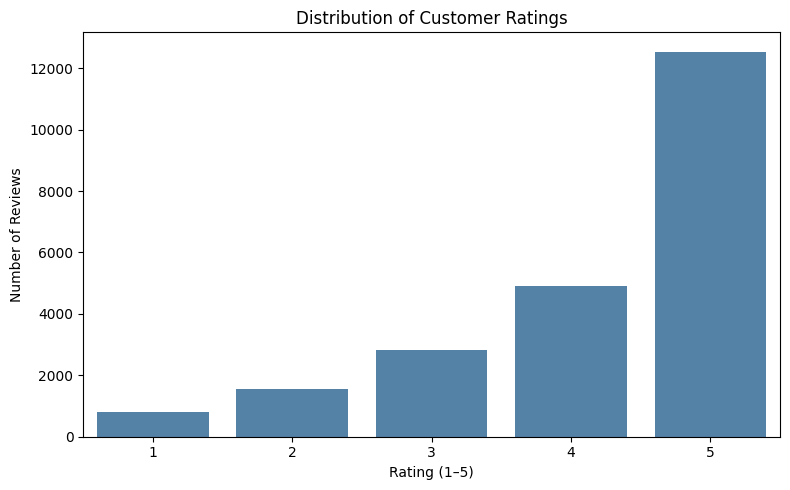

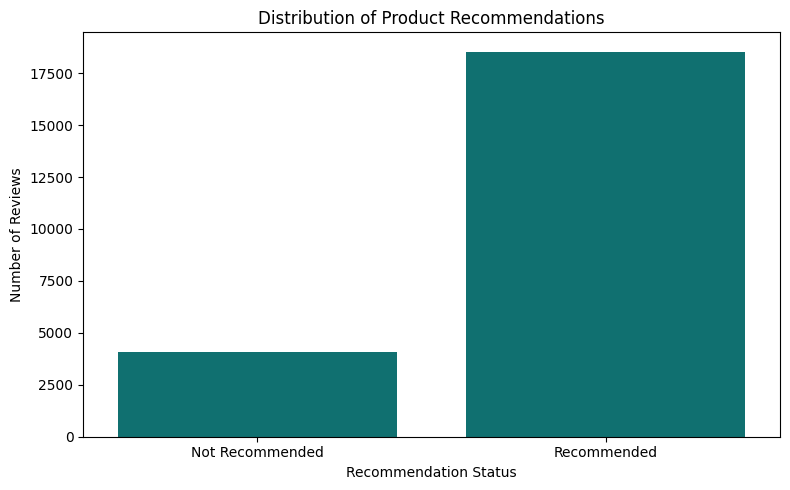

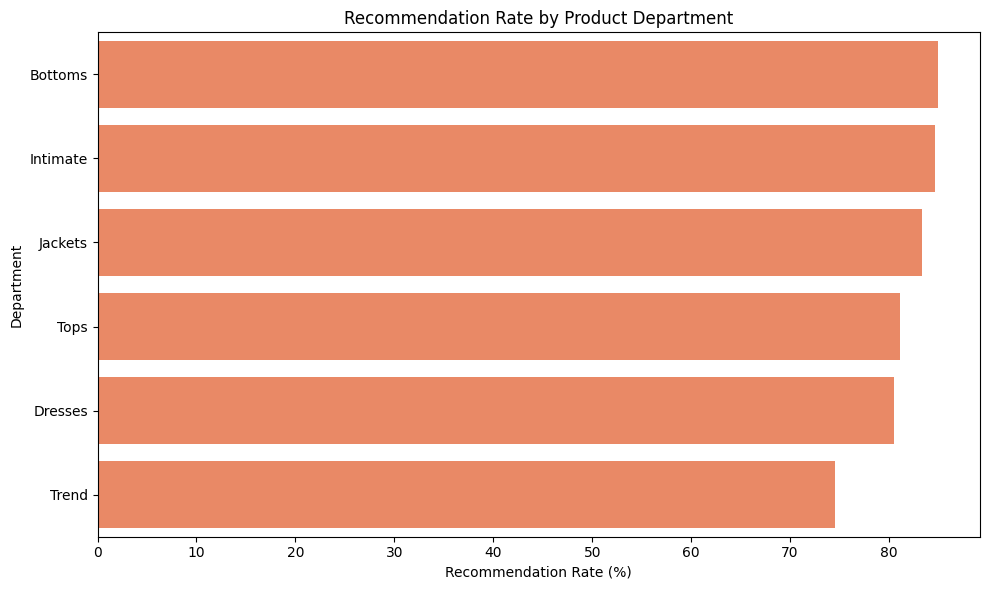

EDA SUMMARY
----------------------------------------
Total reviews: 22,640
Average rating: 4.18 / 5
Recommendation rate: 81.89%

Recommendation rate by department:


,Department Name,Recommendation Rate (%)
0,Bottoms,84.95
1,Intimate,84.63
2,Jackets,83.33
3,Tops,81.07
4,Dresses,80.52
5,Trend,74.58


In [ ]:
# ============================================================
# STEP 4: EXPLORATORY DATA ANALYSIS (EDA)
# ============================================================

# 1. Customer rating distribution
plt.figure(figsize=(8, 5))

sns.countplot(data=df_clean, x="Rating", color="steelblue")

plt.title("Distribution of Customer Ratings")
plt.xlabel("Rating (1–5)")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()


# 2. Product recommendation distribution
recommendation_labels = {
    0: "Not Recommended",
    1: "Recommended"
}

df_clean["Recommendation Status"] = (
    df_clean["Recommended IND"].map(recommendation_labels)
)

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_clean,
    x="Recommendation Status",
    order=["Not Recommended", "Recommended"],
    color="teal"
)

plt.title("Distribution of Product Recommendations")
plt.xlabel("Recommendation Status")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()


# 3. Recommendation rate by department
department_recommendation = (
    df_clean.groupby("Department Name")["Recommended IND"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
    .reset_index(name="Recommendation Rate (%)")
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=department_recommendation,
    x="Recommendation Rate (%)",
    y="Department Name",
    color="coral"
)

plt.title("Recommendation Rate by Product Department")
plt.xlabel("Recommendation Rate (%)")
plt.ylabel("Department")
plt.tight_layout()
plt.show()


# 4. Summary statistics
print("EDA SUMMARY")
print("-" * 40)

print(f"Total reviews: {len(df_clean):,}")
print(f"Average rating: {df_clean['Rating'].mean():.2f} / 5")

print(
    f"Recommendation rate: "
    f"{df_clean['Recommended IND'].mean() * 100:.2f}%"
)

print("\nRecommendation rate by department:")
display(department_recommendation.round(2))

# STEP 5: TEXT PREPROCESSING

This stage prepares customer reviews for text analytics by converting text to lowercase, removing irrelevant characters, tokenizing words, removing stopwords, and applying lemmatization.

The original review text is retained for reference.

In [ ]:
# ============================================================
# STEP 5: TEXT PREPROCESSING
# ============================================================

import re
import nltk

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

# Download required NLTK resources
nltk.download("stopwords", quiet=True)
nltk.download("wordnet", quiet=True)
nltk.download("omw-1.4", quiet=True)

# Initialize preprocessing tools
stop_words = set(stopwords.words("english"))

# Retain negation words because they affect sentiment
stop_words -= {"no", "not", "nor"}

lemmatizer = WordNetLemmatizer()


# 1. Define the text preprocessing function
def preprocess_text(text):

    # Convert text to lowercase
    text = str(text).lower()

    # Remove HTML tags
    text = re.sub(r"<.*?>", " ", text)

    # Remove URLs
    text = re.sub(r"http\S+|www\S+", " ", text)

    # Extract words while preserving apostrophes
    tokens = re.findall(r"\b[a-z]+(?:'[a-z]+)?\b", text)

    # Remove stopwords and lemmatize words
    processed_tokens = [
        lemmatizer.lemmatize(word)
        for word in tokens
        if word not in stop_words
    ]

    return " ".join(processed_tokens)


# 2. Apply preprocessing to customer reviews
df_clean["Cleaned Review"] = df_clean["Review Text"].apply(
    preprocess_text
)


# 3. Compare original and processed reviews
print("TEXT PREPROCESSING RESULTS")
print("-" * 50)

display(
    df_clean[["Review Text", "Cleaned Review"]].head(10)
)


# 4. Check for empty processed reviews
empty_reviews = (df_clean["Cleaned Review"].str.strip() == "").sum()

print("\nPREPROCESSING SUMMARY")
print(f"Total reviews processed: {len(df_clean):,}")
print(f"Empty processed reviews: {empty_reviews:,}")
print(
    f"Average original review length: "
    f"{df_clean['Review Text'].str.split().str.len().mean():.2f} words"
)
print(
    f"Average processed review length: "
    f"{df_clean['Cleaned Review'].str.split().str.len().mean():.2f} words"
)

TEXT PREPROCESSING RESULTS
--------------------------------------------------


,Review Text,Cleaned Review
0,Absolutely wonderful - silky and sexy and comf...,absolutely wonderful silky sexy comfortable
1,Love this dress! it's sooo pretty. i happene...,love dress sooo pretty happened find store gla...
2,I had such high hopes for this dress and reall...,high hope dress really wanted work initially o...
3,"I love, love, love this jumpsuit. it's fun, fl...",love love love jumpsuit fun flirty fabulous ev...
4,This shirt is very flattering to all due to th...,shirt flattering due adjustable front tie perf...
5,"I love tracy reese dresses, but this one is no...",love tracy reese dress one not petite foot tal...
6,I aded this in my basket at hte last mintue to...,aded basket hte last mintue see would look lik...
7,"I ordered this in carbon for store pick up, an...",ordered carbon store pick ton stuff always try...
8,I love this dress. i usually get an xs but it ...,love dress usually get x run little snug bust ...
9,"I'm 5""5' and 125 lbs. i ordered the s petite t...",lb ordered petite make sure length long typica...



PREPROCESSING SUMMARY
Total reviews processed: 22,640
Empty processed reviews: 0
Average original review length: 60.20 words
Average processed review length: 28.66 words


# STEP 6: TEXT ANALYSIS — FREQUENT WORDS AND PHRASES

This stage identifies frequently occurring words (unigrams) and two-word phrases (bigrams) in customer reviews to explore recurring themes in customer feedback.

TOP 15 MOST FREQUENT WORDS


,Word,Frequency
0,dress,11432
1,fit,10174
2,not,9799
3,size,9438
4,love,9001
5,top,8366
6,like,7174
7,color,6987
8,look,6914
9,wear,6537


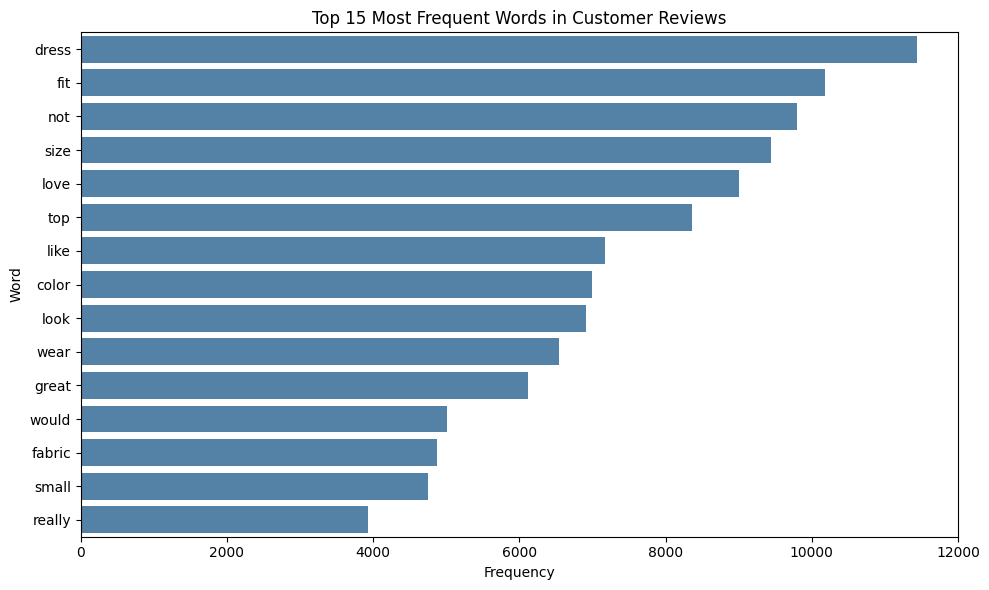


TOP 15 MOST FREQUENT TWO-WORD PHRASES


,Bigram,Frequency
0,true size,1348
1,fit perfectly,1090
2,look great,901
3,look like,806
4,love dress,743
5,usually wear,692
6,fit well,663
7,well made,607
8,fit great,586
9,size fit,572


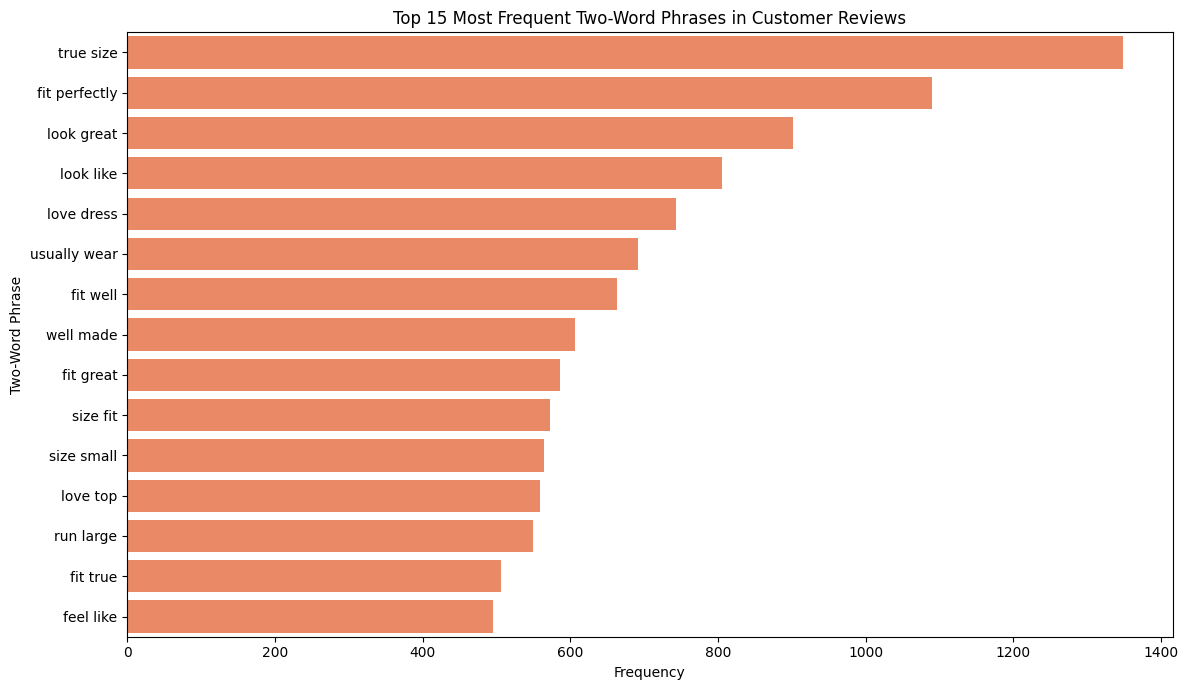

In [ ]:
# ============================================================
# STEP 6: TEXT ANALYSIS — FREQUENT WORDS AND PHRASES
# ============================================================

from collections import Counter
from sklearn.feature_extraction.text import CountVectorizer

# ------------------------------------------------------------
# 1. FREQUENT WORDS (UNIGRAMS)
# ------------------------------------------------------------

# Split cleaned reviews into individual words
all_words = [
    word
    for review in df_clean["Cleaned Review"]
    for word in review.split()
]

# Count word frequencies
word_counts = Counter(all_words)

# Extract the 15 most frequent words
top_words = pd.DataFrame(
    word_counts.most_common(15),
    columns=["Word", "Frequency"]
)

print("TOP 15 MOST FREQUENT WORDS")
display(top_words)


# Visualize frequent words
plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_words,
    x="Frequency",
    y="Word",
    color="steelblue"
)

plt.title("Top 15 Most Frequent Words in Customer Reviews")
plt.xlabel("Frequency")
plt.ylabel("Word")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 2. FREQUENT TWO-WORD PHRASES (BIGRAMS)
# ------------------------------------------------------------

# Create a bigram vectorizer
bigram_vectorizer = CountVectorizer(
    ngram_range=(2, 2),
    min_df=10,
    max_features=5000
)

# Fit the vectorizer and count bigram occurrences
bigram_matrix = bigram_vectorizer.fit_transform(
    df_clean["Cleaned Review"]
)

# Calculate total frequency of each bigram
bigram_frequencies = bigram_matrix.sum(axis=0).A1

bigram_counts = pd.DataFrame({
    "Bigram": bigram_vectorizer.get_feature_names_out(),
    "Frequency": bigram_frequencies
})

# Extract the 15 most frequent bigrams
top_bigrams = (
    bigram_counts
    .sort_values("Frequency", ascending=False)
    .head(15)
    .reset_index(drop=True)
)

print("\nTOP 15 MOST FREQUENT TWO-WORD PHRASES")
display(top_bigrams)


# Visualize frequent bigrams
plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_bigrams,
    x="Frequency",
    y="Bigram",
    color="coral"
)

plt.title("Top 15 Most Frequent Two-Word Phrases in Customer Reviews")
plt.xlabel("Frequency")
plt.ylabel("Two-Word Phrase")
plt.tight_layout()
plt.show()

# STEP 7: SENTIMENT ANALYSIS

This stage uses VADER sentiment analysis to classify customer reviews as positive, neutral, or negative based on their sentiment scores.

The analysis will explore the relationship between customer sentiment and product recommendations.

SENTIMENT DISTRIBUTION


,Sentiment,Count
0,Positive,20986
1,Neutral,277
2,Negative,1377


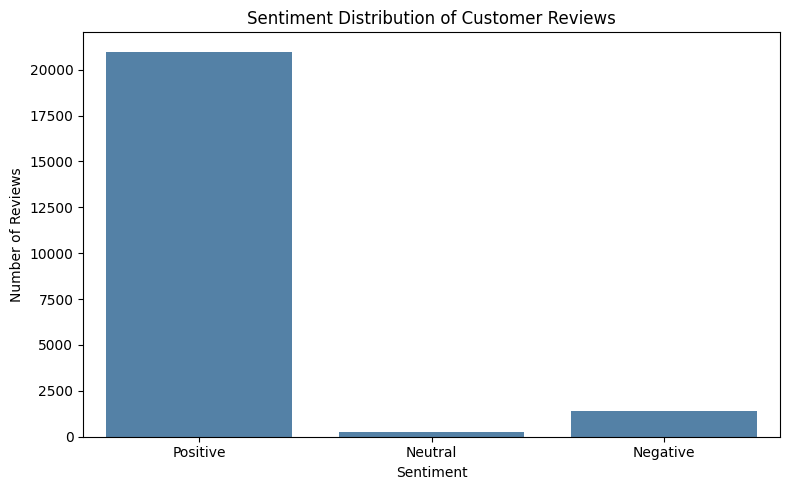


RECOMMENDATION RATE BY SENTIMENT


,Sentiment,count,Recommendation Rate (%)
0,Negative,1377,34.86
1,Neutral,277,47.29
2,Positive,20986,85.43


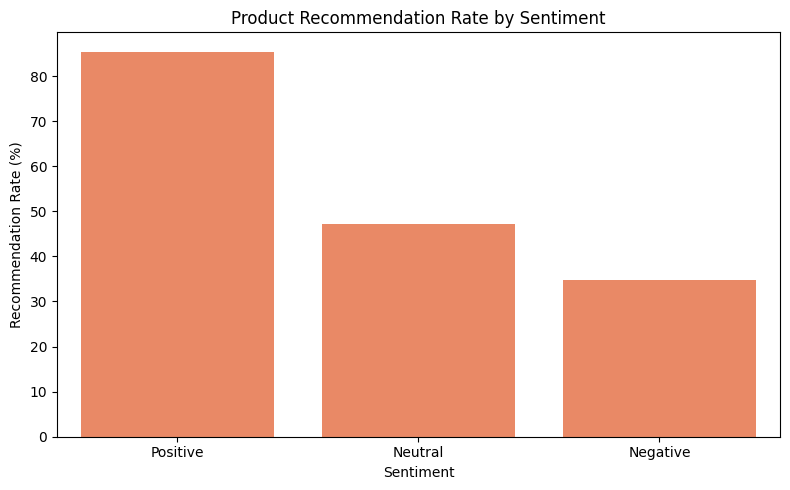


SENTIMENT ANALYSIS SUMMARY
----------------------------------------
Average sentiment score: 0.736
Positive reviews: 20,986
Neutral reviews: 277
Negative reviews: 1,377


In [ ]:
# ============================================================
# STEP 7: SENTIMENT ANALYSIS USING VADER
# ============================================================

import nltk
from nltk.sentiment.vader import SentimentIntensityAnalyzer

# Download VADER lexicon
nltk.download("vader_lexicon", quiet=True)

# Initialize sentiment analyzer
sia = SentimentIntensityAnalyzer()


# ------------------------------------------------------------
# 1. CALCULATE SENTIMENT SCORES
# ------------------------------------------------------------

# Use original review text for sentiment analysis
sentiment_scores = df_clean["Review Text"].apply(
    lambda text: sia.polarity_scores(str(text))
)

# Extract compound sentiment score
df_clean["Sentiment Score"] = sentiment_scores.apply(
    lambda scores: scores["compound"]
)


# ------------------------------------------------------------
# 2. CLASSIFY SENTIMENT
# ------------------------------------------------------------

def classify_sentiment(score):
    if score >= 0.05:
        return "Positive"
    elif score <= -0.05:
        return "Negative"
    else:
        return "Neutral"

df_clean["Sentiment"] = df_clean["Sentiment Score"].apply(
    classify_sentiment
)


# ------------------------------------------------------------
# 3. SENTIMENT DISTRIBUTION
# ------------------------------------------------------------

sentiment_counts = (
    df_clean["Sentiment"]
    .value_counts()
    .reindex(["Positive", "Neutral", "Negative"], fill_value=0)
    .reset_index()
)

sentiment_counts.columns = ["Sentiment", "Count"]

print("SENTIMENT DISTRIBUTION")
display(sentiment_counts)


# ------------------------------------------------------------
# 4. VISUALIZE SENTIMENT DISTRIBUTION
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

sns.barplot(
    data=sentiment_counts,
    x="Sentiment",
    y="Count",
    color="steelblue"
)

plt.title("Sentiment Distribution of Customer Reviews")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 5. SENTIMENT VS PRODUCT RECOMMENDATION
# ------------------------------------------------------------

sentiment_recommendation = (
    df_clean.groupby("Sentiment")["Recommended IND"]
    .agg(["count", "mean"])
    .reset_index()
)

sentiment_recommendation["Recommendation Rate (%)"] = (
    sentiment_recommendation["mean"] * 100
)

sentiment_recommendation = sentiment_recommendation[
    ["Sentiment", "count", "Recommendation Rate (%)"]
]

print("\nRECOMMENDATION RATE BY SENTIMENT")
display(sentiment_recommendation.round(2))


# ------------------------------------------------------------
# 6. VISUALIZE RECOMMENDATION RATE BY SENTIMENT
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

sns.barplot(
    data=sentiment_recommendation,
    x="Sentiment",
    y="Recommendation Rate (%)",
    order=["Positive", "Neutral", "Negative"],
    color="coral"
)

plt.title("Product Recommendation Rate by Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Recommendation Rate (%)")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 7. SUMMARY
# ------------------------------------------------------------

print("\nSENTIMENT ANALYSIS SUMMARY")
print("-" * 40)
print(f"Average sentiment score: {df_clean['Sentiment Score'].mean():.3f}")
print(f"Positive reviews: {(df_clean['Sentiment'] == 'Positive').sum():,}")
print(f"Neutral reviews: {(df_clean['Sentiment'] == 'Neutral').sum():,}")
print(f"Negative reviews: {(df_clean['Sentiment'] == 'Negative').sum():,}")

# STEP 8: TF-IDF FEATURE EXTRACTION

This stage converts preprocessed customer reviews into numerical feature vectors using TF-IDF.

The dataset is split into training and testing sets before fitting the vectorizer. This ensures that the vocabulary and feature weights are learned only from the training data.

In [ ]:
# ============================================================
# STEP 8: TF-IDF FEATURE EXTRACTION
# ============================================================

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

# ------------------------------------------------------------
# 1. DEFINE FEATURES AND TARGET
# ------------------------------------------------------------

X_text = df_clean["Cleaned Review"]
y = df_clean["Recommended IND"]

print("DATASET FOR MODELING")
print("-" * 40)
print(f"Total reviews: {len(df_clean):,}")
print(f"Target variable: Recommended IND")


# ------------------------------------------------------------
# 2. SPLIT DATA INTO TRAINING AND TESTING SETS
# ------------------------------------------------------------

X_train_text, X_test_text, y_train, y_test = train_test_split(
    X_text,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTRAIN-TEST SPLIT")
print("-" * 40)
print(f"Training reviews: {len(X_train_text):,}")
print(f"Testing reviews:  {len(X_test_text):,}")


# ------------------------------------------------------------
# 3. APPLY TF-IDF VECTORIZATION
# ------------------------------------------------------------

tfidf_vectorizer = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    min_df=5,
    max_df=0.95
)

# Learn vocabulary and weights using training data only
X_train_tfidf = tfidf_vectorizer.fit_transform(X_train_text)

# Transform testing data using the fitted vectorizer
X_test_tfidf = tfidf_vectorizer.transform(X_test_text)


# ------------------------------------------------------------
# 4. DISPLAY FEATURE EXTRACTION RESULTS
# ------------------------------------------------------------

print("\nTF-IDF FEATURE EXTRACTION SUMMARY")
print("-" * 40)
print(f"Training matrix shape: {X_train_tfidf.shape}")
print(f"Testing matrix shape:  {X_test_tfidf.shape}")
print(f"Vocabulary size: {len(tfidf_vectorizer.get_feature_names_out()):,}")

# Display sample vocabulary terms
print("\nSAMPLE VOCABULARY TERMS")
print(tfidf_vectorizer.get_feature_names_out()[:30])

DATASET FOR MODELING
----------------------------------------
Total reviews: 22,640
Target variable: Recommended IND

TRAIN-TEST SPLIT
----------------------------------------
Training reviews: 18,112
Testing reviews:  4,528

TF-IDF FEATURE EXTRACTION SUMMARY
----------------------------------------
Training matrix shape: (18112, 5000)
Testing matrix shape:  (4528, 5000)
Vocabulary size: 5,000

SAMPLE VOCABULARY TERMS
['able' 'able get' 'able try' 'able wear' 'absolute' 'absolutely'
 'absolutely adore' 'absolutely beautiful' 'absolutely gorgeous'
 'absolutely love' 'absolutely loved' 'absolutely perfect'
 'absolutely stunning' 'accent' 'accentuate' 'accentuated' 'accentuates'
 'accessory' 'accommodate' 'according' 'accurate' 'accurately' 'across'
 'across back' 'across bust' 'across chest' 'across shoulder' 'actual'
 'actually' 'actually fit']


# STEP 9: MODEL BUILDING — LOGISTIC REGRESSION

This stage trains a Logistic Regression classifier using TF-IDF features extracted from customer reviews.

The model predicts the product recommendation label (Recommended IND) using review text.

Class weighting is applied to account for the imbalance between the two target classes.

In [ ]:
# ============================================================
# STEP 9: MODEL BUILDING — LOGISTIC REGRESSION
# ============================================================

from sklearn.linear_model import LogisticRegression

# ------------------------------------------------------------
# 1. INITIALIZE THE MODEL
# ------------------------------------------------------------

logistic_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)


# ------------------------------------------------------------
# 2. TRAIN THE MODEL
# ------------------------------------------------------------

print("TRAINING LOGISTIC REGRESSION MODEL...")

logistic_model.fit(X_train_tfidf, y_train)

print("Model training completed successfully!")


# ------------------------------------------------------------
# 3. GENERATE PREDICTIONS
# ------------------------------------------------------------

y_pred = logistic_model.predict(X_test_tfidf)

# Predicted probabilities for the positive class
y_prob = logistic_model.predict_proba(X_test_tfidf)[:, 1]


# ------------------------------------------------------------
# 4. DISPLAY SAMPLE PREDICTIONS
# ------------------------------------------------------------

prediction_results = pd.DataFrame({
    "Review": X_test_text.reset_index(drop=True).head(10),
    "Actual Recommendation": y_test.reset_index(drop=True).head(10),
    "Predicted Recommendation": y_pred[:10]
})

print("\nSAMPLE MODEL PREDICTIONS")
display(prediction_results)

TRAINING LOGISTIC REGRESSION MODEL...
Model training completed successfully!

SAMPLE MODEL PREDICTIONS


,Review,Actual Recommendation,Predicted Recommendation
0,like sweater like others owned returned good q...,1,0
1,slip easily soft flattering definitely go dress,1,1
2,pant pair well anything dress boot sandal bewa...,1,1
3,first kudos reviewer setting expectation color...,1,0
4,great jacket warm coat yet thin enough wear in...,1,1
5,like way vest look flattering color nice like ...,1,1
6,dress incredible let say first arrived terrifi...,1,1
7,tried dress store mango color opted order blue...,1,1
8,little hesitant ordered dress needed something...,1,1
9,ordered quite nice cardigan received sweater p...,1,1


# STEP 10: MODEL EVALUATION

This stage evaluates the Logistic Regression classifier using accuracy, precision, recall, F1-score, ROC-AUC, and a confusion matrix.

The evaluation uses the held-out test dataset to assess the model's ability to predict product recommendations from customer review text.

MODEL PERFORMANCE METRICS
----------------------------------------


,Metric,Score
0,Accuracy,0.8695
1,Precision,0.9593
2,Recall,0.8778
3,F1-Score,0.9168
4,ROC-AUC,0.9286



CLASSIFICATION REPORT
----------------------------------------
                 precision    recall  f1-score   support

Not Recommended       0.60      0.83      0.70       820
    Recommended       0.96      0.88      0.92      3708

       accuracy                           0.87      4528
      macro avg       0.78      0.85      0.81      4528
   weighted avg       0.89      0.87      0.88      4528


CONFUSION MATRIX
----------------------------------------
[[ 682  138]
 [ 453 3255]]


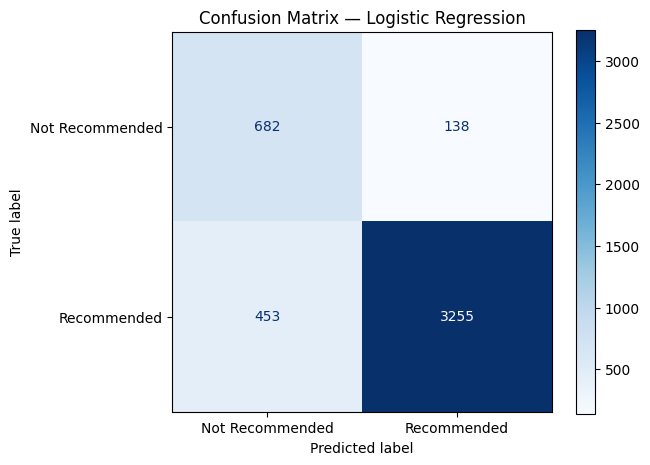


EVALUATION SUMMARY
----------------------------------------
Accuracy:  0.8695
Precision: 0.9593
Recall:    0.8778
F1-Score:  0.9168
ROC-AUC:   0.9286


In [ ]:
# ============================================================
# STEP 10: MODEL EVALUATION
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# ------------------------------------------------------------
# 1. CALCULATE PERFORMANCE METRICS
# ------------------------------------------------------------

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_test, y_prob)

evaluation_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC"
    ],
    "Score": [
        accuracy,
        precision,
        recall,
        f1,
        roc_auc
    ]
})

evaluation_results["Score"] = evaluation_results["Score"].round(4)

print("MODEL PERFORMANCE METRICS")
print("-" * 40)
display(evaluation_results)


# ------------------------------------------------------------
# 2. CLASSIFICATION REPORT
# ------------------------------------------------------------

print("\nCLASSIFICATION REPORT")
print("-" * 40)

print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Not Recommended", "Recommended"],
        zero_division=0
    )
)


# ------------------------------------------------------------
# 3. CONFUSION MATRIX
# ------------------------------------------------------------

cm = confusion_matrix(y_test, y_pred)

print("\nCONFUSION MATRIX")
print("-" * 40)
print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Recommended", "Recommended"]
).plot(cmap="Blues", values_format="d")

plt.title("Confusion Matrix — Logistic Regression")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 4. SUMMARY
# ------------------------------------------------------------

print("\nEVALUATION SUMMARY")
print("-" * 40)
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-Score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")

# STEP 11: MODEL INTERPRETATION — KEYWORDS ASSOCIATED WITH RECOMMENDATIONS

This stage examines Logistic Regression coefficients to identify the words and phrases most strongly associated with recommended and non-recommended reviews.

Positive coefficients indicate an association with the recommended class, while negative coefficients indicate an association with the not-recommended class.

TOP 15 FEATURES ASSOCIATED WITH RECOMMENDED REVIEWS


,Word or Phrase,Coefficient
2389,love,6.511778
3078,perfect,5.525984
713,comfortable,4.559328
1746,great,4.509584
2252,little,3.744983
754,compliment,3.628024
4563,unique,3.622188
3974,soft,3.607239
1507,flattering,3.357952
739,comfy,3.153469



TOP 15 FEATURES ASSOCIATED WITH NOT-RECOMMENDED REVIEWS


,Word or Phrase,Coefficient
993,disappointed,-6.003721
4663,wanted love,-5.601428
3470,returning,-5.087592
3468,returned,-4.882906
2806,not flattering,-4.813242
587,cheap,-4.139747
1684,going back,-4.086716
4555,unflattering,-4.011139
224,bad,-3.730942
3466,return,-3.701359


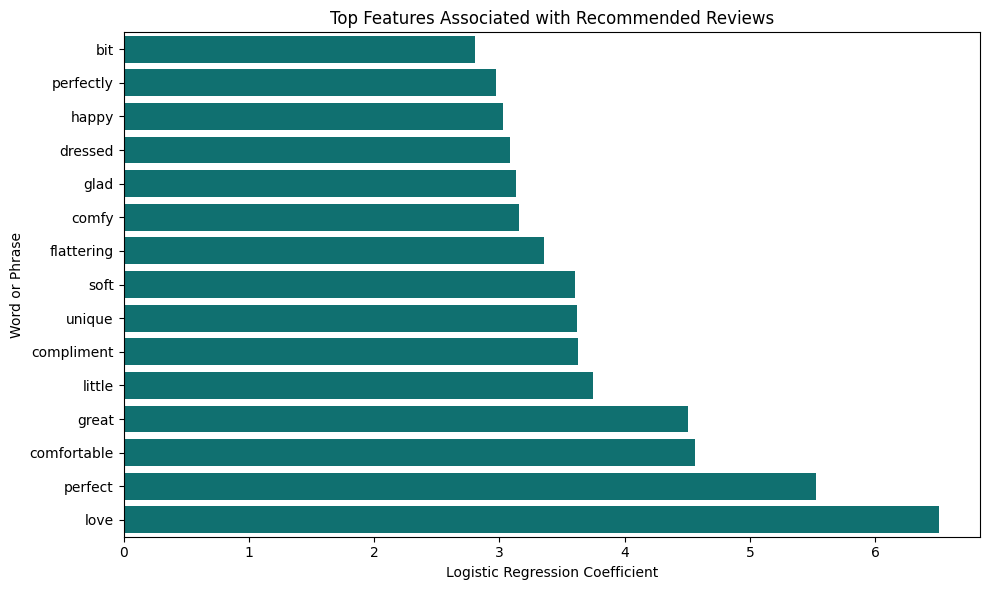

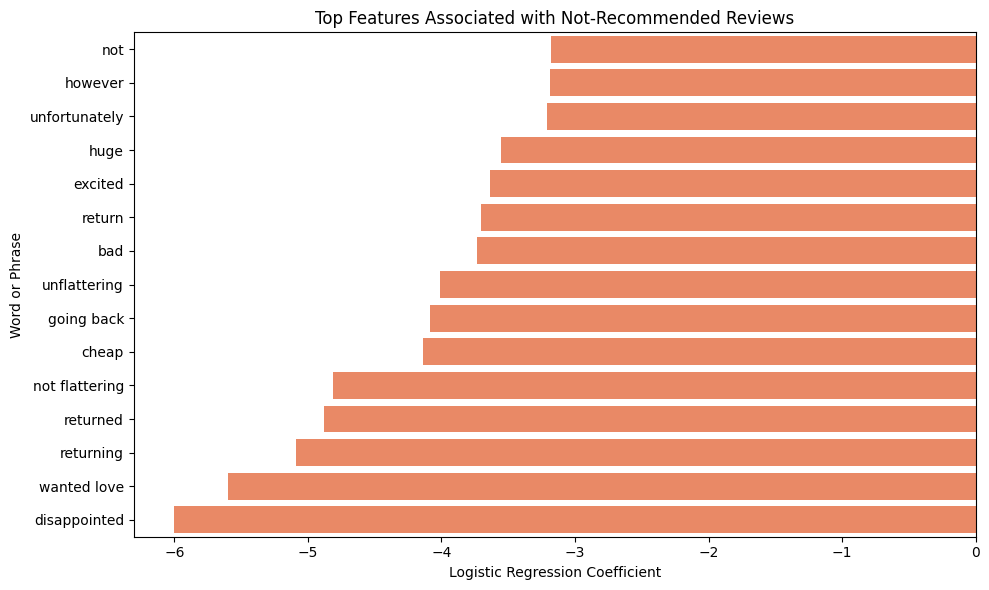

In [ ]:
# ============================================================
# STEP 11: MODEL INTERPRETATION — KEYWORD IMPORTANCE
# ============================================================

# ------------------------------------------------------------
# 1. EXTRACT FEATURE COEFFICIENTS
# ------------------------------------------------------------

feature_names = tfidf_vectorizer.get_feature_names_out()
coefficients = logistic_model.coef_[0]

feature_importance = pd.DataFrame({
    "Word or Phrase": feature_names,
    "Coefficient": coefficients
})


# ------------------------------------------------------------
# 2. TOP FEATURES ASSOCIATED WITH RECOMMENDATIONS
# ------------------------------------------------------------

top_recommended = (
    feature_importance
    .sort_values("Coefficient", ascending=False)
    .head(15)
    .sort_values("Coefficient", ascending=True)
)

print("TOP 15 FEATURES ASSOCIATED WITH RECOMMENDED REVIEWS")
display(top_recommended.sort_values("Coefficient", ascending=False))


# ------------------------------------------------------------
# 3. TOP FEATURES ASSOCIATED WITH NOT RECOMMENDED REVIEWS
# ------------------------------------------------------------

top_not_recommended = (
    feature_importance
    .sort_values("Coefficient", ascending=True)
    .head(15)
    .sort_values("Coefficient", ascending=False)
)

print("\nTOP 15 FEATURES ASSOCIATED WITH NOT-RECOMMENDED REVIEWS")
display(top_not_recommended.sort_values("Coefficient", ascending=True))


# ------------------------------------------------------------
# 4. VISUALIZE RECOMMENDED FEATURES
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_recommended,
    x="Coefficient",
    y="Word or Phrase",
    color="teal"
)

plt.title("Top Features Associated with Recommended Reviews")
plt.xlabel("Logistic Regression Coefficient")
plt.ylabel("Word or Phrase")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 5. VISUALIZE NOT-RECOMMENDED FEATURES
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_not_recommended,
    x="Coefficient",
    y="Word or Phrase",
    color="coral"
)

plt.title("Top Features Associated with Not-Recommended Reviews")
plt.xlabel("Logistic Regression Coefficient")
plt.ylabel("Word or Phrase")
plt.tight_layout()
plt.show()

# STEP 12: BASELINE MODEL COMPARISON

A Dummy Classifier is used as a baseline to compare the Logistic Regression model against a simple majority-class prediction strategy.

The comparison helps establish whether the trained model provides meaningful predictive value beyond the class distribution.

In [ ]:
# ============================================================
# STEP 12: BASELINE MODEL COMPARISON
# ============================================================

from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score
import numpy as np

# ------------------------------------------------------------
# 1. TRAIN THE BASELINE MODEL
# ------------------------------------------------------------

baseline_model = DummyClassifier(strategy="most_frequent")

# Dummy inputs: the baseline uses only the target labels
baseline_model.fit(
    np.zeros((len(y_train), 1)),
    y_train
)

baseline_predictions = baseline_model.predict(
    np.zeros((len(y_test), 1))
)


# ------------------------------------------------------------
# 2. COMPARE MODEL PERFORMANCE
# ------------------------------------------------------------

comparison = pd.DataFrame({
    "Model": ["Dummy Classifier", "Logistic Regression"],
    "Accuracy": [
        accuracy_score(y_test, baseline_predictions),
        accuracy_score(y_test, y_pred)
    ],
    "F1-Score": [
        f1_score(y_test, baseline_predictions, zero_division=0),
        f1_score(y_test, y_pred, zero_division=0)
    ]
})

print("BASELINE VS LOGISTIC REGRESSION")
display(comparison.round(4))

BASELINE VS LOGISTIC REGRESSION


,Model,Accuracy,F1-Score
0,Dummy Classifier,0.8189,0.9004
1,Logistic Regression,0.8695,0.9168


# STEP 13: BUSINESS INSIGHTS AND RECOMMENDATIONS

## Key Business Insights

1. Customer satisfaction: Words such as "love", "perfect", "comfortable", and "great" are strongly associated with product recommendations.

2. Product fit and quality: Negative expressions such as "unflattering", "cheap", and "disappointed" are associated with non-recommendation.

3. Returns and dissatisfaction: Terms such as "returned", "returning", and "going back" indicate dissatisfaction and potential product-return concerns.

4. Recommendation patterns: Positive reviews have a higher recommendation rate than negative reviews, indicating a strong association between sentiment and customer recommendation behavior.

5. Predictive performance: Logistic Regression achieves 86.95% accuracy, compared with 81.89% for the majority-class baseline.

## Business Recommendations

1. Improve product descriptions by providing accurate information about fabric, fit, sizing, and garment appearance.

2. Use recurring negative review themes to identify potential product quality and fit issues.

3. Strengthen sizing guidance through size charts, fit descriptions, and customer feedback.

4. Use review sentiment and recommendation patterns to monitor customer satisfaction across product departments.

5. Incorporate review-text insights into product development and customer experience decisions.

## Limitations

1. The dataset contains more recommended than non-recommended reviews, creating class imbalance.

2. The model identifies associations between review text and recommendations, not causal relationships.

3. The dataset represents a particular retailer and may not generalize to other retailers.

4. Sentiment classification and text preprocessing may not fully capture context, sarcasm, or nuanced customer opinions.

5. Model performance should be interpreted alongside class-specific metrics and the baseline comparison.

# STEP 14: SENTIMENT AND CLASS IMBALANCE VALIDATION

This step examines the distribution of sentiment labels and recommendation outcomes to identify class imbalance and understand how sentiment relates to customer ratings.

In [ ]:
# ============================================================
# STEP 14: SENTIMENT AND CLASS IMBALANCE VALIDATION
# ============================================================

# 1. SENTIMENT DISTRIBUTION
print("SENTIMENT DISTRIBUTION")
print("-" * 50)

sentiment_counts = df_clean["Sentiment"].value_counts()
sentiment_percentages = (
    df_clean["Sentiment"].value_counts(normalize=True) * 100
)

sentiment_summary = pd.DataFrame({
    "Count": sentiment_counts,
    "Percentage (%)": sentiment_percentages.round(2)
})

display(sentiment_summary)


# 2. RECOMMENDATION CLASS DISTRIBUTION
print("\nRECOMMENDATION CLASS DISTRIBUTION")
print("-" * 50)

recommendation_summary = pd.DataFrame({
    "Count": df_clean["Recommended IND"].value_counts(),
    "Percentage (%)": (
        df_clean["Recommended IND"].value_counts(normalize=True) * 100
    ).round(2)
})

display(recommendation_summary)


# 3. SENTIMENT VS CUSTOMER RATINGS
print("\nSENTIMENT VS CUSTOMER RATINGS")
print("-" * 50)

sentiment_rating_table = pd.crosstab(
    df_clean["Sentiment"],
    df_clean["Rating"],
    normalize="index"
) * 100

display(sentiment_rating_table.round(2))


# 4. MAJORITY CLASS BASELINE
print("\nMAJORITY CLASS BASELINE")
print("-" * 50)

majority_class_accuracy = (
    df_clean["Recommended IND"].value_counts(normalize=True).max()
    * 100
)

print(
    f"Majority class accuracy: "
    f"{majority_class_accuracy:.2f}%"
)

SENTIMENT DISTRIBUTION
--------------------------------------------------


,Count,Percentage (%)
Sentiment,,
Positive,20986,92.69
Negative,1377,6.08
Neutral,277,1.22



RECOMMENDATION CLASS DISTRIBUTION
--------------------------------------------------


,Count,Percentage (%)
Recommended IND,,
1,18539,81.89
0,4101,18.11



SENTIMENT VS CUSTOMER RATINGS
--------------------------------------------------


Rating,1,2,3,4,5
Sentiment,,,,,
Negative,20.62,23.82,27.96,15.76,11.84
Neutral,11.55,19.86,30.32,20.22,18.05
Positive,2.41,5.56,11.22,22.09,58.73



MAJORITY CLASS BASELINE
--------------------------------------------------
Majority class accuracy: 81.89%
